# Ligand-receptor interactions at the tumour-nerve interface

LIANA spatial co-expression -> pseudobulk -> statistics (Kruskal-Wallis plus
pairwise Mann-Whitney, FDR-corrected) -> patient concordance -> Tier 1 / Tier 2
definitions -> master table and gene/background exports for the ORA
(03_LR_interface_ORA.Rmd) -> figures.

Tier 1 pairs are used for the ORA and for the pairs shown in the figures. The
selection criteria are those reported in the Methods.


## 1. Setup and imports

In [1]:
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"   # must be set before h5py/anndata are imported (network drives)

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams["pdf.fonttype"] = 42   # editable TrueType text in PDFs (Illustrator)
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
import matplotlib.cm as cm
import liana as li
import os
from scipy.sparse import issparse
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu
import statsmodels.stats.multitest as mt


## 2. Paths

`ANNDATA_FILE` points to the original, read-only source data (loading never modifies it). All outputs are written to a separate, dedicated folder.

In [2]:
# Paths are relative to the project folder (the one containing input/).
# Run this notebook from there.
INPUT_FOLDER = 'input'
DATA_FOLDER  = os.path.join('output', 'data')
FIG_FOLDER   = os.path.join('output', 'figures')

# clean_adata.h5ad is written by 05c_deconvolution_composition_figures.Rmd
# (spatial_data_processing).
ANNDATA_FILE = os.path.join(INPUT_FOLDER, 'clean_adata.h5ad')

# Section used for the single-section illustrative panels (Figure S10A-C)
SAMPLE = '6249bl18_noPNIandhighPNI'

os.makedirs(DATA_FOLDER, exist_ok=True)
os.makedirs(FIG_FOLDER, exist_ok=True)


## 3. Load data (read-only)

In [3]:
adata = sc.read(ANNDATA_FILE)
adata


AnnData object with n_obs × n_vars = 78212 × 18054
    obs: 'X.1', 'X', 'barcode', 'in_tissue', 'array_row', 'array_col', 'sample_id', 'patient_id', 'type', 'sum', 'detected', 'subsets_Mito_sum', 'subsets_Mito_detected', 'subsets_Mito_percent', 'subsets_HBB_sum', 'subsets_HBB_detected', 'subsets_HBB_percent', 'total', 'sample_label', 'QCPass', 'sizeFactor', 'max_nmf', 'k30label', 'nerve', 'tumor', 'is.nerve', 'col', 'row', 'NerveID', 'mnTumor', 'Invaded', 'BorderID', 'BorderInvaded', 'by', 'NerveProximal', 'InvadedNerve', 'Nerve', 'tumorProximalCells', 'TumorDistal', 'TumorDistalID', 'Area', 'invasion', 'plasma', 'DRAXIN_lev', 'C1qM'
    var: 'symbol'
    uns: 'X_name'
    obsm: 'compk30'
    layers: 'counts'

## 4. Spatial neighbour graph

In [4]:
sp = np.ndarray(shape=(78212,2))
sp[:,0] = np.array(adata.obs['col'])
sp[:,1] = np.array(adata.obs['row'])
adata.obsm['spatial'] = sp
li.ut.spatial_neighbors(adata, bandwidth=1.5, cutoff=0.1, kernel='exponential', set_diag=True)


### Illustrative single-section panels (Figure S10A-C)


In [ ]:
# Figure S10A -- spatial connectivity of one spot, in one section, showing the
# neighbourhood the exponential kernel defines.
fig = li.pl.connectivity(adata[adata.obs['sample_id'] == SAMPLE], idx=0, size=0.4)
fig.save(os.path.join(FIG_FOLDER, 'FigureS10A_spatial_connectivity.pdf'),
         dpi=300, bbox_inches='tight')
fig


## 5. LR bivariate co-expression (LIANA)

In [5]:
li.mt.lr_bivar(adata,
               function_name='cosine',
               n_perms=None,
               mask_negatives=True,
               add_categories=True,
               expr_prop=0.0001,
               use_raw=False,
               verbose=True
               )

lrdata = adata.obsm['local_scores']


Using resource `consensus`.
Using `.X`!
Converting to sparse csr matrix!
['TBCE_ENSG00000285053', 'TBCE_ENSG00000284770', 'HSPA14_ENSG00000284024', 'HSPA14_ENSG00000187522', 'TMSB15B_ENSG00000158427', 'TMSB15B_ENSG00000269226'] contain `_`. Consider replacing those!
anndata/_core/anndata.py:1113: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
anndata/_core/anndata.py:1113: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
anndata/_core/anndata.py:1113: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
anndata/_core/anndata.py:1113: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
anndata/_core/anndata.py:1113: FutureWarning: is_cate

In [ ]:
# Figure S10B -- log-normalised MMP7 and CD151 expression in the same section.
sc.pl.spatial(
    adata[adata.obs['sample_id'] == SAMPLE],
    color=['MMP7', 'CD151'],
    spot_size=1,
    cmap='viridis',
    show=False
)
fig = plt.gcf()
fig.savefig(os.path.join(FIG_FOLDER, 'FigureS10B_MMP7_CD151_expression.pdf'),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)


In [ ]:
# Figure S10C (spatial panel) -- local MMP7^CD151 cosine similarity per spot.
sub = lrdata[lrdata.obs['sample_id'] == SAMPLE]

fig = plt.figure()
ax = fig.add_subplot(111)
sc.pl.spatial(
    sub,
    color=['MMP7^CD151'],
    size=1.4,
    spot_size=1,
    cmap='viridis',
    ax=ax,
    show=False
)
fig.savefig(os.path.join(FIG_FOLDER, 'FigureS10C_MMP7_CD151_spatial_cosine.pdf'),
            dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)


## 6. Nerve/Tumour group assignment

In [7]:
def clean_categorical_id(series):
    series = series.replace(-2147483648, np.nan)
    series = series.astype("string").fillna("none")
    def normalize(x):
        if x == "none":
            return x
        if isinstance(x, str) and x.endswith(".0"):
            x = x[:-2]
        return x
    series = series.map(normalize)
    vals = series.unique().tolist()
    nums = sorted([v for v in vals if v != "none"], key=lambda x: int(x))
    cats = ["none"] + nums
    return pd.Categorical(series, categories=cats)

lrdata.obs['NerveID'] = clean_categorical_id(lrdata.obs['NerveID'])
lrdata.obs['TumorDistalID'] = clean_categorical_id(lrdata.obs['TumorDistalID'])


In [8]:
# GroupID assignment
lrdata.obs['GroupID'] = ["Nerve_" + x for x in lrdata.obs['NerveID']]
tumID = ["Tumor_" + x for x in lrdata.obs['TumorDistalID'][lrdata.obs['NerveID']=="none"]]
lrdata.obs.loc[lrdata.obs.NerveID=='none','GroupID'] = tumID
lrdata.obs['Group'] = lrdata.obs['Invaded']
tumGroup = lrdata.obs['TumorDistalID'].apply(lambda x: 'Tumor' if x != 'none' else 'none')
lrdata.obs['Group'] = lrdata.obs['Group'].cat.add_categories(['Tumor','none'])
lrdata.obs.loc[lrdata.obs['Group'].isna(), 'Group'] = tumGroup[lrdata.obs['Group'].isna()]
print(pd.crosstab(lrdata.obs['Group'], lrdata.obs['GroupID']))


GroupID     Nerve_1  Nerve_10  Nerve_102  Nerve_105  Nerve_106  Nerve_11  \
Group                                                                      
Invaded           0         0          5          3          0         0   
NonInvaded       20        79          0          0          5         7   
Tumor             0         0          0          0          0         0   
none              0         0          0          0          0         0   

GroupID     Nerve_112  Nerve_115  Nerve_116  Nerve_118  ...  Tumor_88  \
Group                                                   ...             
Invaded             0          2          2          0  ...         0   
NonInvaded          4          0          0          3  ...         0   
Tumor               0          0          0          0  ...         6   
none                0          0          0          0  ...         0   

GroupID     Tumor_9  Tumor_90  Tumor_91  Tumor_92  Tumor_93  Tumor_96  \
Group                          

## 7. Pseudobulk (nerve/tumour-patch level)

In [9]:
import decoupler as dc

pdata = dc.get_pseudobulk(
    lrdata,
    sample_col='sample_id',
    groups_col='GroupID',
    mode='mean',
    min_cells=3,
    min_counts=0,
    skip_checks=True
)
print(pdata)


decoupler/utils_anndata.py:181: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


AnnData object with n_obs × n_vars = 176 × 4372
    obs: 'in_tissue', 'sample_id', 'patient_id', 'type', 'sample_label', 'QCPass', 'NerveID', 'mnTumor', 'Invaded', 'by', 'InvadedNerve', 'Nerve', 'TumorDistal', 'TumorDistalID', 'DRAXIN_lev', 'GroupID', 'Group', 'psbulk_n_cells', 'psbulk_counts'
    layers: 'psbulk_props'


anndata/_core/anndata.py:1113: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead


In [14]:
# Save the pseudobulk object (with patient_id), so the statistics and figures
# (section 8) can be re-run later without repeating LIANA (sections 3-7).
sample_to_patient = lrdata.obs.drop_duplicates('sample_id').set_index('sample_id')['patient_id']
pdata.obs['patient_id'] = pdata.obs['sample_id'].map(sample_to_patient).astype(str)
keep_cols = [c for c in ['Group', 'patient_id', 'sample_id', 'GroupID'] if c in pdata.obs.columns]
pdata_save = ad.AnnData(X=pdata.X.copy(),
                        obs=pdata.obs[keep_cols].astype(str).copy(),
                        var=pd.DataFrame(index=pdata.var_names.astype(str)))
PDATA_FILE = os.path.join(DATA_FOLDER, 'LR_pseudobulk_pdata.h5ad')
pdata_save.write_h5ad(PDATA_FILE)
print("Saved:", PDATA_FILE, pdata_save.shape)


... storing 'Group' as categorical
... storing 'patient_id' as categorical
... storing 'sample_id' as categorical
... storing 'GroupID' as categorical


Saved: output/data/LR_pseudobulk_pdata.h5ad (176, 4372)


To resume later: restart the kernel, run sections 1-2 (imports, paths), then section 8 -- it loads the saved pseudobulk object if `pdata` is not in memory.


---
## 8. FINAL analysis: master table, tiers, gene exports, figures

Everything below is the single, final, disclosed pipeline. Depends only on `pdata` and `lrdata` from the cells above.

Loaded saved pseudobulk object: (176, 4372)
Tested 4366 LR pairs (skipped 6 degenerate/untestable pairs)
Checking patient concordance for 1819 pairs with >=1 significant contrast


/tmp/ipykernel_322532/2228412892.py:121: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pm = sub.groupby(['patient_id', 'Group'])['Cosine'].mean().unstack()
/tmp/ipykernel_322532/2228412892.py:121: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pm = sub.groupby(['patient_id', 'Group'])['Cosine'].mean().unstack()
/tmp/ipykernel_322532/2228412892.py:121: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pm = sub.groupby(['patien


Master table saved: 4366 pairs, 18 columns

Tier 1 (interface-specific): 130 pairs
Tier 2 (tumour-exposure candidates): 108 pairs

SANITY CHECK -- Tier 1 patient concordance:
  Low concordance vs NonInvaded: 0 of 130
  Low concordance vs Tumor: 0 of 130
  PASSED: all Tier 1 pairs show consistent direction of effect in >=2/3 patients.

Background: 1771 genes
Tier 1 query genes: 134 | Tier 2 query genes: 140


seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group

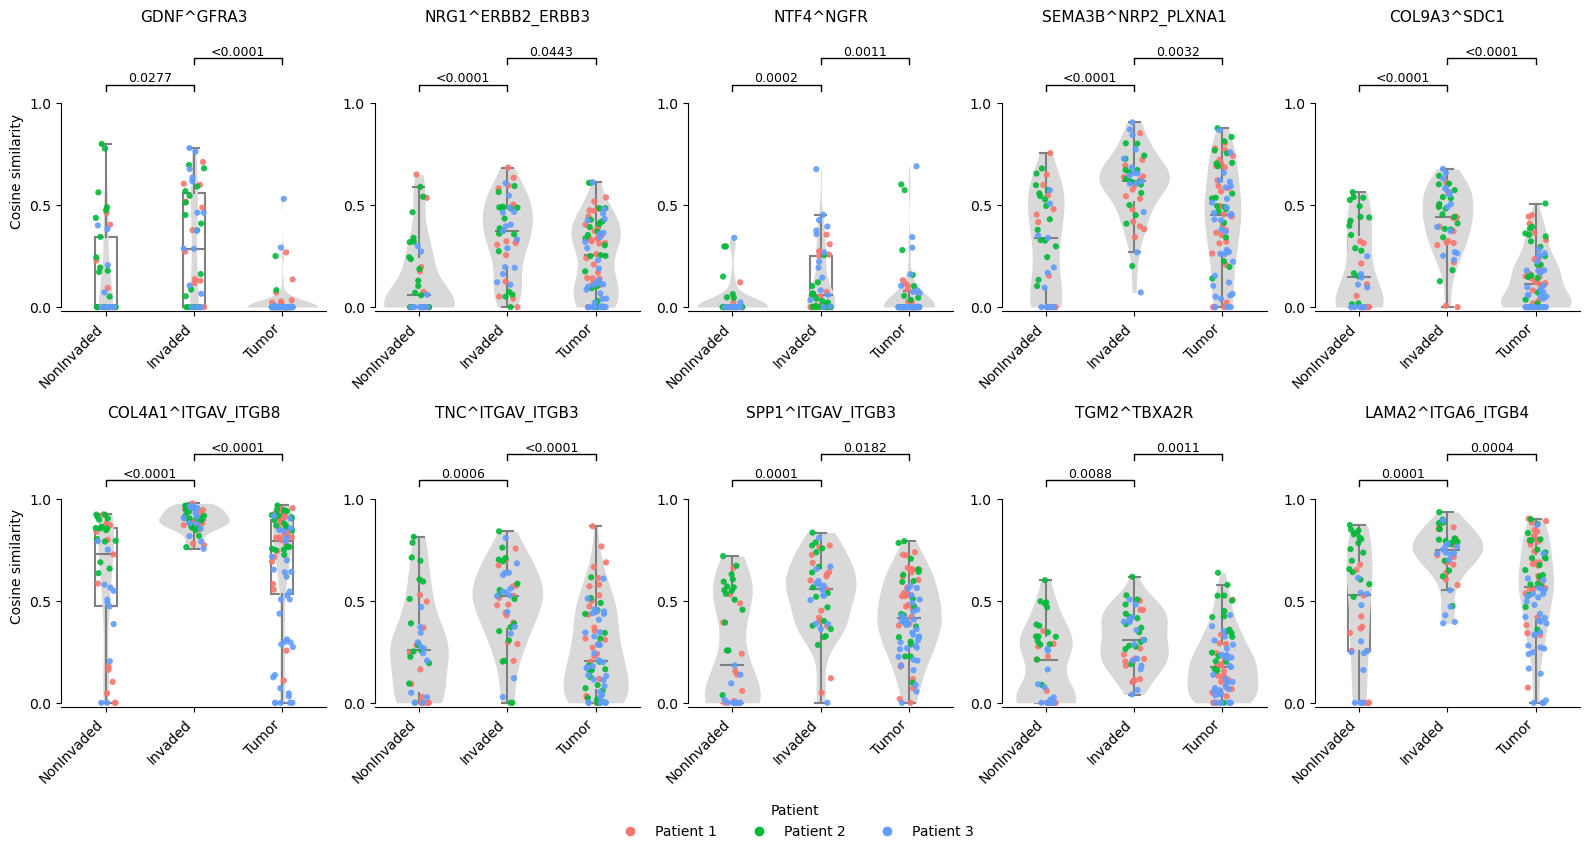

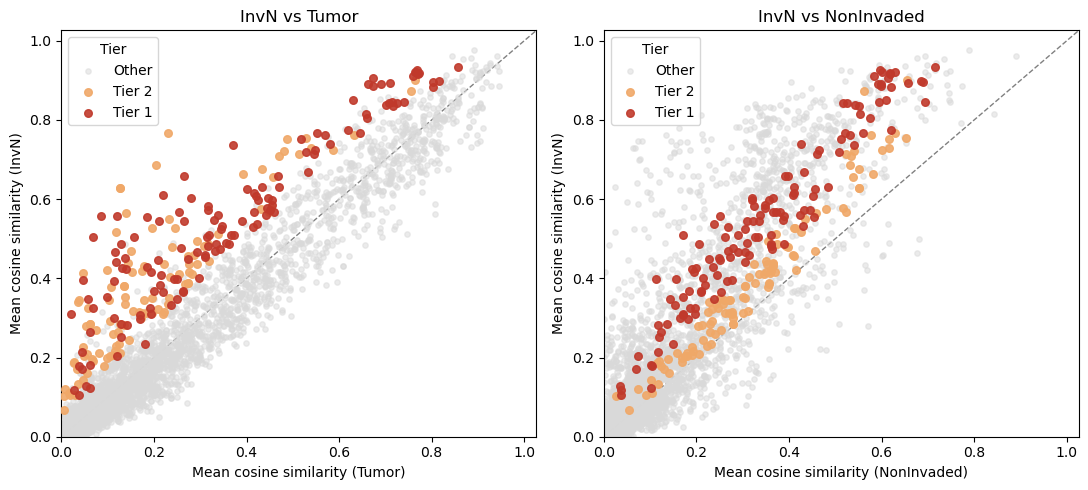


=== Pipeline complete. Files in output folders: ===
Data: ['LR_pseudobulk_pdata.h5ad', 'SpatialLR_MASTER_TABLE.csv', 'LR_background_genes.csv', 'LR_query_genes_Tier2_FINAL.csv', 'SpatialLR_Tier1_FINAL.csv', 'SpatialLR_Tier2_FINAL.csv', 'LR_query_genes_Tier1_FINAL.csv']
Figures: ['COL4A1_ITGAV_ITGB8_styled.pdf', 'CLCF1_CRLF1_styled.pdf', '.ipynb_checkpoints', 'MMP7_CD151_styled.pdf', 'LR_deviation_from_diagonal_FINAL.pdf', 'LR_deviation_from_diagonal_Tier1_only.pdf', 'COL9A3_SDC1_styled.pdf', 'SPP1_ITGAV_ITGB3_styled.pdf', 'GDNF_GFRA3_styled.pdf', 'LAMA4_ITGA6_ITGB4_styled.pdf', 'TNC_ITGAV_ITGB3_styled.pdf', 'SEMA3B_NRP2_PLXNA1_styled.pdf', 'LR_selected_pairs_grid.pdf', 'LAMB1_ITGA6_ITGB4_styled.pdf', 'LAMA2_ITGA6_ITGB4_styled.pdf', 'NTF4_NGFR_styled.pdf', 'NRG1_ERBB2_ERBB3_styled.pdf', 'TGM2_TBXA2R_styled.pdf']


In [1]:
# FINAL LR analysis pipeline: master table, tiers, gene/background
# exports, and figure regeneration.
#
# DEPENDS ON: pdata (pseudobulk LR scores). If it is not in memory, the saved
# LR_pseudobulk_pdata.h5ad (written after the pseudobulk step) is loaded, so
# this section can be re-run without repeating LIANA.
# ======================================================================

import os
# The data folder is on a network drive that does not support HDF5 file
# locking ("unable to lock file, errno = 121"). Must be set BEFORE h5py /
# anndata are imported; reading below also opens the file with locking off.
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"
import h5py
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu
import statsmodels.stats.multitest as mt

# Paths (DATA_FOLDER, FIG_FOLDER) are set in section 2.

# ---- Patient/group settings, set once, used everywhere downstream ------
patient_order   = ['54703', '6249', '70865']
patient_labels  = {'54703': 'Patient 1', '6249': 'Patient 2', '70865': 'Patient 3'}
patient_palette = {'54703': '#F8766D', '6249': '#00BA38', '70865': '#619CFF'}
group_order     = ['NonInvaded', 'Invaded', 'Tumor']

# Ensure patient_id is present and correctly typed on pdata.obs (patient_id
# can come through as int32 from the underlying AnnData object -- must be
# cast to string to match patient_order, or pd.Categorical silently
# converts every value to NaN)
if 'pdata' not in globals():                       # resume without re-running LIANA
    _f = os.path.join(DATA_FOLDER, 'LR_pseudobulk_pdata.h5ad')
    with h5py.File(_f, "r", locking=False) as _h5:          # read-only, no file lock (network drive)
        _read_elem = getattr(getattr(ad, "io", None), "read_elem", None) or ad.experimental.read_elem
        pdata = _read_elem(_h5)
    print("Loaded saved pseudobulk object:", pdata.shape)
if 'patient_id' not in pdata.obs.columns:
    sample_to_patient = lrdata.obs.drop_duplicates('sample_id').set_index('sample_id')['patient_id']
    pdata.obs['patient_id'] = pdata.obs['sample_id'].map(sample_to_patient)
pdata.obs['patient_id'] = pdata.obs['patient_id'].astype(str)


# ======================================================================
# 1. Full statistical test per LR pair -- Kruskal-Wallis (3-group) plus
# pairwise Mann-Whitney (Invaded vs NonInvaded, Invaded vs Tumor), with
# FDR correction. This is the core computation feeding everything else.
# ======================================================================
results = []
skipped = 0

for interaction in pdata.var_names:
    vals = {}
    for cat in group_order:
        mask = pdata.obs['Group'] == cat
        vals[cat] = pdata.X[mask, pdata.var_names == interaction].flatten()

    groups_for_test = [v for v in vals.values() if len(v) >= 2]
    if len(groups_for_test) < 2:
        skipped += 1
        continue

    try:
        stat, p = kruskal(*groups_for_test)
    except ValueError:
        # All values identical across groups (e.g. an all-zero interaction)
        skipped += 1
        continue

    if len(vals['Invaded']) >= 2 and len(vals['NonInvaded']) >= 2:
        try:
            _, p_inv_vs_ni = mannwhitneyu(vals['Invaded'], vals['NonInvaded'])
        except ValueError:
            p_inv_vs_ni = np.nan
    else:
        p_inv_vs_ni = np.nan

    if len(vals['Invaded']) >= 2 and len(vals['Tumor']) >= 2:
        try:
            _, p_inv_vs_tumor = mannwhitneyu(vals['Invaded'], vals['Tumor'])
        except ValueError:
            p_inv_vs_tumor = np.nan
    else:
        p_inv_vs_tumor = np.nan

    results.append({
        'Interaction': interaction,
        'KW_stat': stat, 'KW_p': p,
        'Invaded_vs_NonInvaded_p': p_inv_vs_ni,
        'Invaded_vs_Tumor_p': p_inv_vs_tumor,
        'mean_Invaded': np.mean(vals['Invaded']) if len(vals['Invaded']) else np.nan,
        'mean_NonInvaded': np.mean(vals['NonInvaded']) if len(vals['NonInvaded']) else np.nan,
        'mean_Tumor': np.mean(vals['Tumor']) if len(vals['Tumor']) else np.nan,
        'n_Invaded': len(vals['Invaded']), 'n_NonInvaded': len(vals['NonInvaded']), 'n_Tumor': len(vals['Tumor'])
    })

stats_df = pd.DataFrame(results)
stats_df['KW_padj']      = mt.multipletests(stats_df['KW_p'].fillna(1), method='fdr_bh')[1]
stats_df['InvVsNI_padj'] = mt.multipletests(stats_df['Invaded_vs_NonInvaded_p'].fillna(1), method='fdr_bh')[1]
stats_df['InvVsTumor_padj'] = mt.multipletests(stats_df['Invaded_vs_Tumor_p'].fillna(1), method='fdr_bh')[1]
stats_df.sort_values('InvVsNI_padj', inplace=True)

print(f"Tested {len(stats_df)} LR pairs (skipped {skipped} degenerate/untestable pairs)")


# ======================================================================
# 2. Patient concordance -- for every pair with >=1 significant contrast,
# check whether the direction of effect (Invaded higher) agrees in >=2 of
# 3 patients. Reported as an informational column, not used as a filter.
# ======================================================================
def check_concordance(interaction, pdata):
    sub = pdata.obs[['Group', 'patient_id']].copy()
    sub['Cosine'] = pdata.X[:, pdata.var_names == interaction].flatten()
    pm = sub.groupby(['patient_id', 'Group'])['Cosine'].mean().unstack()
    if not all(c in pm.columns for c in group_order):
        return np.nan, np.nan
    return (pm['Invaded'] > pm['NonInvaded']).sum(), (pm['Invaded'] > pm['Tumor']).sum()


significant_mask = (stats_df['InvVsNI_padj'] < 0.05) | (stats_df['InvVsTumor_padj'] < 0.05)
pairs_to_check = stats_df.loc[significant_mask, 'Interaction']
print(f"Checking patient concordance for {len(pairs_to_check)} pairs with >=1 significant contrast")

concordance_results = [
    {'Interaction': p, **dict(zip(['n_patients_agree_vs_NI', 'n_patients_agree_vs_Tumor'],
                                  check_concordance(p, pdata)))}
    for p in pairs_to_check
]
concordance_df = pd.DataFrame(concordance_results)

stats_df = stats_df.merge(concordance_df, on='Interaction', how='left')


def flag_concordance(padj, n_agree):
    if pd.isna(padj) or padj >= 0.05:
        return "Not significant"
    if pd.isna(n_agree):
        return "Could not assess"
    return "Low (<2/3 patients)" if n_agree < 2 else "High (>=2/3 patients)"


stats_df['Concordance_vs_NonInvaded'] = stats_df.apply(
    lambda r: flag_concordance(r['InvVsNI_padj'], r['n_patients_agree_vs_NI']), axis=1)
stats_df['Concordance_vs_Tumor'] = stats_df.apply(
    lambda r: flag_concordance(r['InvVsTumor_padj'], r['n_patients_agree_vs_Tumor']), axis=1)

# ---- Save the master table: every tested pair, full stats + concordance ----
stats_df.to_csv(os.path.join(DATA_FOLDER, 'SpatialLR_MASTER_TABLE.csv'), index=False)
print(f"\nMaster table saved: {len(stats_df)} pairs, {stats_df.shape[1]} columns")


# ======================================================================
# 3. Tier definitions (original, significance-based; unchanged) with a
# concordance sanity check reported alongside -- not applied as a filter.
#
#   Tier 1: interface-specific -- significant AND Invaded is the maximum,
#           on BOTH contrasts (vs NonInvaded and vs Tumor).
#   Tier 2: tumour-exposure candidates -- significant + max vs Tumor only;
#           broader nerve-general molecules a tumour cell could plausibly
#           encounter, not claimed as interface-specific biology.
# ======================================================================
tier1_confirmed = stats_df[
    (stats_df['KW_padj'] < 0.05) &
    (stats_df['InvVsNI_padj'] < 0.05) &
    (stats_df['InvVsTumor_padj'] < 0.05) &
    (stats_df['mean_Invaded'] > stats_df['mean_NonInvaded']) &
    (stats_df['mean_Invaded'] > stats_df['mean_Tumor'])
].sort_values('InvVsNI_padj')

tier2_suggestive = stats_df[
    (stats_df['InvVsTumor_padj'] < 0.05) &
    (stats_df['mean_Invaded'] > stats_df['mean_Tumor']) &
    (stats_df['mean_Invaded'] > stats_df['mean_NonInvaded']) &
    ~stats_df['Interaction'].isin(tier1_confirmed['Interaction'])
].sort_values('InvVsTumor_padj')

print(f"\nTier 1 (interface-specific): {len(tier1_confirmed)} pairs")
print(f"Tier 2 (tumour-exposure candidates): {len(tier2_suggestive)} pairs")

# ---- Sanity check: Tier 1 patient concordance ----
n_low_ni    = (tier1_confirmed['Concordance_vs_NonInvaded'] == 'Low (<2/3 patients)').sum()
n_low_tumor = (tier1_confirmed['Concordance_vs_Tumor'] == 'Low (<2/3 patients)').sum()
print(f"\nSANITY CHECK -- Tier 1 patient concordance:")
print(f"  Low concordance vs NonInvaded: {n_low_ni} of {len(tier1_confirmed)}")
print(f"  Low concordance vs Tumor: {n_low_tumor} of {len(tier1_confirmed)}")
if n_low_ni == 0 and n_low_tumor == 0:
    print("  PASSED: all Tier 1 pairs show consistent direction of effect in >=2/3 patients.")
else:
    print("  WARNING -- inspect flagged pairs before finalizing:")
    print(tier1_confirmed[(tier1_confirmed['Concordance_vs_NonInvaded'] == 'Low (<2/3 patients)') |
                          (tier1_confirmed['Concordance_vs_Tumor'] == 'Low (<2/3 patients)')])

tier1_confirmed.to_csv(os.path.join(DATA_FOLDER, 'SpatialLR_Tier1_FINAL.csv'), index=False)
tier2_suggestive.to_csv(os.path.join(DATA_FOLDER, 'SpatialLR_Tier2_FINAL.csv'), index=False)


# ======================================================================
# 4. Gene parsing (handles multi-subunit complexes: '_' within a side,
# '^' between ligand and receptor) + background/query gene exports for R
# ======================================================================
def parse_lr_pair(pair_str):
    ligand_side, sep, receptor_side = pair_str.partition('^')
    return ligand_side.split('_'), receptor_side.split('_')


def all_genes_from_pairs(pairs):
    genes = set()
    for pair in pairs:
        lig, rec = parse_lr_pair(pair)
        genes.update(lig); genes.update(rec)
    return sorted(genes)


background_genes  = all_genes_from_pairs(stats_df['Interaction'])
query_genes_tier1 = all_genes_from_pairs(tier1_confirmed['Interaction'])
query_genes_tier2 = all_genes_from_pairs(tier2_suggestive['Interaction'])

print(f"\nBackground: {len(background_genes)} genes")
print(f"Tier 1 query genes: {len(query_genes_tier1)} | Tier 2 query genes: {len(query_genes_tier2)}")

pd.DataFrame({'gene': background_genes}).to_csv(os.path.join(DATA_FOLDER, 'LR_background_genes.csv'), index=False)
pd.DataFrame({'gene': query_genes_tier1}).to_csv(os.path.join(DATA_FOLDER, 'LR_query_genes_Tier1_FINAL.csv'), index=False)
pd.DataFrame({'gene': query_genes_tier2}).to_csv(os.path.join(DATA_FOLDER, 'LR_query_genes_Tier2_FINAL.csv'), index=False)


# ======================================================================
# 5. Figure regeneration
# ======================================================================

# ---- 5a. Styled violin/box/patient-jitter plot for selected pairs ------
def format_pvalue(p):
    if pd.isna(p):
        return None
    return "<0.0001" if p < 0.0001 else f"{p:.4f}"


def add_significance_bracket(ax, x1, x2, y, text, height):
    ax.plot([x1, x1, x2, x2], [y, y + height, y + height, y], lw=1, color='black')
    ax.text((x1 + x2) / 2, y + height, text, ha='center', va='bottom', fontsize=9)


# Same y-axis for every pair: ticks 0.0 / 0.5 / 1.0, axis line from 0 to 1,
# significance brackets drawn above 1.0 at fixed heights (same space in all panels)
Y_TICKS = [0.0, 0.5, 1.0]
Y_TOP   = 1.0      # top of the data axis (cosine similarity <= 1)


def plot_lr_pair_styled(interaction, pdata, stats_row=None, save_name=None, ax=None, show_legend=True):
    sub_df = pdata.obs[['Group', 'patient_id']].copy()
    sub_df['Cosine'] = pdata.X[:, pdata.var_names == interaction].flatten()
    sub_df = sub_df[sub_df['Group'].isin(group_order)]

    sub_df['patient_id'] = sub_df['patient_id'].astype(str)
    sub_df['patient_id'] = pd.Categorical(sub_df['patient_id'], categories=patient_order, ordered=True)
    sub_df['Group'] = pd.Categorical(sub_df['Group'], categories=group_order, ordered=True)

    if ax is None:
        fig, ax = plt.subplots(figsize=(4, 5))
    else:
        fig = ax.figure

    sns.violinplot(data=sub_df, x='Group', y='Cosine', order=group_order,
                   color='#D9D9D9', inner=None, cut=0, linewidth=0, ax=ax)
    sns.boxplot(data=sub_df, x='Group', y='Cosine', order=group_order,
               width=0.25, showfliers=False, boxprops=dict(facecolor='white', edgecolor='grey'),
               medianprops=dict(color='grey'), whiskerprops=dict(color='grey'),
               capprops=dict(color='grey'), ax=ax)

    np.random.seed(0)
    for patient in patient_order:
        sub = sub_df[sub_df['patient_id'] == patient]
        if len(sub) == 0:
            continue
        x_positions = sub['Group'].apply(lambda g: group_order.index(g)).to_numpy(dtype=int)
        jittered_x = x_positions + np.random.uniform(-0.12, 0.12, size=len(x_positions))
        ax.scatter(jittered_x, sub['Cosine'], color=patient_palette[patient],
                  s=20, alpha=0.9, label=patient_labels[patient], zorder=3, edgecolor='none')

    y_bottom = min(0.0, sub_df['Cosine'].min())
    y_range = Y_TOP - y_bottom
    bracket_height = y_range * 0.03
    current_y = Y_TOP + y_range * 0.06

    if stats_row is not None:
        for x1, x2, p in [(0, 1, stats_row.get('InvVsNI_padj', np.nan)),
                         (1, 2, stats_row.get('InvVsTumor_padj', np.nan))]:
            label = format_pvalue(p)
            if label is not None:
                add_significance_bracket(ax, x1, x2, current_y, label, bracket_height)
                current_y += y_range * 0.13

    ax.set_ylim(y_bottom - 0.02, Y_TOP + y_range * 0.36)   # identical in every panel (room for 2 brackets)
    ax.set_yticks(Y_TICKS)
    ax.set_yticklabels([f"{t:.1f}" for t in Y_TICKS])
    ax.spines['left'].set_bounds(y_bottom, Y_TOP)           # axis line ends at 1.0
    ax.set_title(interaction, fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('Cosine similarity')
    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(group_order, rotation=45, ha='right')
    if show_legend:
        ax.legend(title='Patient', bbox_to_anchor=(1.02, 1), loc='upper left')
    elif ax.get_legend() is not None:
        ax.get_legend().remove()
    sns.despine(ax=ax)
    ax.spines['left'].set_bounds(y_bottom, Y_TOP)
    if save_name:
        plt.tight_layout()
        fig.savefig(os.path.join(FIG_FOLDER, save_name), dpi=600, bbox_inches='tight')
    return fig


# ---- Selected pairs for the figure: 2 rows x 5 pairs, in this order ----
grid_rows = [
    ["GDNF^GFRA3", "NRG1^ERBB2_ERBB3", "NTF4^NGFR", "SEMA3B^NRP2_PLXNA1", "COL9A3^SDC1"],                # top row
    ["COL4A1^ITGAV_ITGB8", "TNC^ITGAV_ITGB3", "SPP1^ITGAV_ITGB3", "TGM2^TBXA2R", "LAMA2^ITGA6_ITGB4"],  # bottom row
]
selected_pairs = [p for row in grid_rows for p in row]
missing = [p for p in selected_pairs if p not in pdata.var_names]
if missing:
    print("WARNING -- selected pairs not in the LR results (left empty in the grid):", missing)

# Individual PDFs (one per pair; not displayed)
for pair in selected_pairs:
    if pair in pdata.var_names:
        row = stats_df[stats_df['Interaction'] == pair].iloc[0] if pair in stats_df['Interaction'].values else None
        plot_lr_pair_styled(pair, pdata, stats_row=row, save_name=f"{pair.replace('^','_')}_styled.pdf")
        plt.close('all')

# ---- All selected pairs in one grid: 2 rows x 5 columns, shared legend ----
n_rows_grid, n_cols_grid = len(grid_rows), max(len(r) for r in grid_rows)
fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(3.2 * n_cols_grid, 4.2 * n_rows_grid), squeeze=False)
for r, row_pairs in enumerate(grid_rows):
    for c in range(n_cols_grid):
        ax = axes[r, c]
        pair = row_pairs[c] if c < len(row_pairs) else None
        if pair is None or pair not in pdata.var_names:
            ax.axis('off')
            continue
        row = stats_df[stats_df['Interaction'] == pair].iloc[0] if pair in stats_df['Interaction'].values else None
        plot_lr_pair_styled(pair, pdata, stats_row=row, ax=ax, show_legend=False)
        if c > 0:
            ax.set_ylabel('')          # y-axis title only on the first panel of each row
handles = [plt.Line2D([0], [0], marker='o', linestyle='', color=patient_palette[p], label=patient_labels[p])
           for p in patient_order]
fig.legend(handles=handles, title='Patient', loc='lower center', ncol=len(patient_order), frameon=False,
           bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(os.path.join(FIG_FOLDER, 'Figure3F_LR_selected_pairs_grid.pdf'), bbox_inches='tight')
plt.show()


# ---- 5b. Deviation-from-diagonal plot, Tier 1 vs Tier 2 vs Other -------
def plot_deviation_from_diagonal(stats_df, tier1_pairs, tier2_pairs, save_name=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    df = stats_df.copy()
    df['tier'] = 'Other'
    df.loc[df['Interaction'].isin(tier2_pairs), 'tier'] = 'Tier 2'
    df.loc[df['Interaction'].isin(tier1_pairs), 'tier'] = 'Tier 1'
    tier_colors = {'Other': '#D9D9D9', 'Tier 2': '#F0A868', 'Tier 1': '#C0392B'}

    for ax, (xcol, xlabel) in zip(axes, [('mean_Tumor', 'Tumor'), ('mean_NonInvaded', 'NonInvaded')]):
        lims = [0, max(df['mean_Invaded'].max(), df[xcol].max()) * 1.05]
        ax.plot(lims, lims, '--', color='grey', linewidth=1, zorder=1)
        for t in ['Other', 'Tier 2', 'Tier 1']:
            sub = df[df['tier'] == t]
            ax.scatter(sub[xcol], sub['mean_Invaded'], s=15 if t == 'Other' else 30,
                      color=tier_colors[t], alpha=0.5 if t == 'Other' else 0.9, label=t,
                      zorder=2 if t == 'Other' else 3)
        ax.set_xlabel(f'Mean cosine similarity ({xlabel})')
        ax.set_ylabel('Mean cosine similarity (InvN)')
        ax.set_title(f'InvN vs {xlabel}')
        ax.set_xlim(lims); ax.set_ylim(lims)
        ax.legend(title='Tier', loc='upper left')

    plt.tight_layout()
    if save_name:
        fig.savefig(os.path.join(FIG_FOLDER, save_name), dpi=300, bbox_inches='tight')
    return fig


fig = plot_deviation_from_diagonal(
    stats_df, tier1_confirmed['Interaction'], tier2_suggestive['Interaction'],
    save_name='exploratory_LR_deviation_from_diagonal_tier1_tier2.pdf'
)
plt.show()

print("\n=== Pipeline complete. Files in output folders: ===")
print("Data:", os.listdir(DATA_FOLDER))
print("Figures:", os.listdir(FIG_FOLDER))


In [ ]:
# Figure S10C (quantification) -- mean MMP7^CD151 cosine similarity per region,
# by group.
plt.close('all')
fig, ax = plt.subplots(figsize=(6, 4))
out = pd.DataFrame([])
for cat in ['Tumor', 'Invaded', 'NonInvaded']:
    expr = pdata.X[pdata.obs['Group'] == cat, pdata.var_names == 'MMP7^CD151']
    out = pd.concat([out, pd.DataFrame({'Group': cat, 'Cosine': expr.flatten()})])

sns.boxplot(data=out, x='Group', y='Cosine', ax=ax).set(
    title='MMP7^CD151', xlabel='', ylabel='Cosine similarity')
plt.tight_layout()
fig.savefig(os.path.join(FIG_FOLDER, 'FigureS10C_MMP7_CD151_cosine_by_group.pdf'),
            dpi=300, bbox_inches='tight')
plt.show()


maxp pruned
cmap pruned
kern dropped
post pruned
FFTM dropped
GPOS pruned
GSUB pruned
glyf pruned
Added gid0 to subset
Added first four glyphs to subset
Closing glyph list over 'GSUB': 34 glyphs before
Glyph names: ['.notdef', '.null', 'I', 'M', 'N', 'O', 'T', 'a', 'c', 'd', 'e', 'eight', 'four', 'h', 'i', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'parenleft', 'parenright', 'period', 'r', 's', 'six', 'space', 't', 'two', 'u', 'v', 'y', 'zero']
Glyph IDs:   [0, 1, 2, 3, 11, 12, 17, 19, 20, 21, 23, 25, 27, 44, 48, 49, 50, 55, 68, 70, 71, 72, 75, 76, 79, 80, 81, 82, 85, 86, 87, 88, 89, 92]
Closed glyph list over 'GSUB': 34 glyphs after
Glyph names: ['.notdef', '.null', 'I', 'M', 'N', 'O', 'T', 'a', 'c', 'd', 'e', 'eight', 'four', 'h', 'i', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'parenleft', 'parenright', 'period', 'r', 's', 'six', 'space', 't', 'two', 'u', 'v', 'y', 'zero']
Glyph IDs:   [0, 1, 2, 3, 11, 12, 17, 19, 20, 21, 23, 25, 27, 44, 48, 49, 50, 55, 68, 70, 71, 72, 75, 7

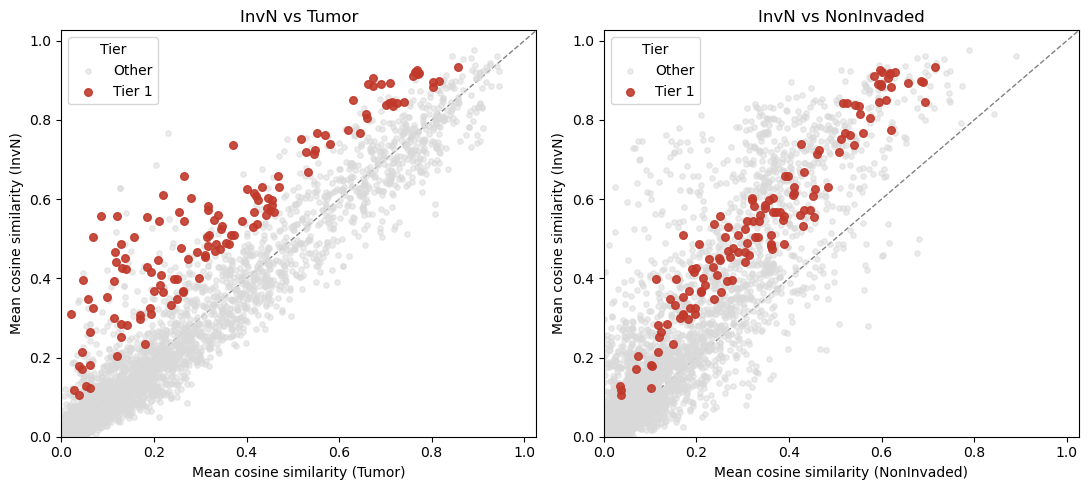


=== Pipeline complete. Files in output folders: ===
Data: ['LR_pseudobulk_pdata.h5ad', 'SpatialLR_MASTER_TABLE.csv', 'LR_background_genes.csv', 'LR_query_genes_Tier2_FINAL.csv', 'SpatialLR_Tier1_FINAL.csv', 'SpatialLR_Tier2_FINAL.csv', 'LR_query_genes_Tier1_FINAL.csv']
Figures: ['COL4A1_ITGAV_ITGB8_styled.pdf', 'CLCF1_CRLF1_styled.pdf', 'MMP7_CD151_styled.pdf', 'LR_deviation_from_diagonal_FINAL.pdf', 'LR_deviation_from_diagonal_Tier1_only.pdf', 'COL9A3_SDC1_styled.pdf', 'GDNF_GFRA3_styled.pdf', 'LAMA4_ITGA6_ITGB4_styled.pdf', 'TNC_ITGAV_ITGB3_styled.pdf', 'SEMA3B_NRP2_PLXNA1_styled.pdf', 'LR_selected_pairs_grid.pdf', 'LAMB1_ITGA6_ITGB4_styled.pdf', 'LAMA2_ITGA6_ITGB4_styled.pdf', 'NTF4_NGFR_styled.pdf', 'NRG1_ERBB2_ERBB3_styled.pdf']


In [13]:
# ---- 5c. Deviation-from-diagonal plot, Tier 1 vs Other -------
def plot_deviation_from_diagonal(stats_df, tier1_pairs, save_name=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    df = stats_df.copy()
    df['tier'] = 'Other'
    df.loc[df['Interaction'].isin(tier1_pairs), 'tier'] = 'Tier 1'

    tier_colors = {'Other': '#D9D9D9', 'Tier 1': '#C0392B'}

    for ax, (xcol, xlabel) in zip(axes, [('mean_Tumor', 'Tumor'), ('mean_NonInvaded', 'NonInvaded')]):
        lims = [0, max(df['mean_Invaded'].max(), df[xcol].max()) * 1.05]
        ax.plot(lims, lims, '--', color='grey', linewidth=1, zorder=1)
        for t in ['Other', 'Tier 1']:
            sub = df[df['tier'] == t]
            ax.scatter(sub[xcol], sub['mean_Invaded'], s=15 if t == 'Other' else 30,
                      color=tier_colors[t], alpha=0.5 if t == 'Other' else 0.9, label=t,
                      zorder=2 if t == 'Other' else 3)
        ax.set_xlabel(f'Mean cosine similarity ({xlabel})')
        ax.set_ylabel('Mean cosine similarity (InvN)')
        ax.set_title(f'InvN vs {xlabel}')
        ax.set_xlim(lims); ax.set_ylim(lims)
        ax.legend(title='Tier', loc='upper left')

    plt.tight_layout()
    if save_name:
        fig.savefig(os.path.join(FIG_FOLDER, save_name), dpi=300, bbox_inches='tight')
    return fig


fig = plot_deviation_from_diagonal(
    stats_df, tier1_confirmed['Interaction'],
    save_name='exploratory_LR_deviation_from_diagonal_tier1_only.pdf'
)
plt.show()

print("\n=== Pipeline complete. Files in output folders: ===")
print("Data:", os.listdir(DATA_FOLDER))
print("Figures:", os.listdir(FIG_FOLDER))